# **Netflix Recommendation System**

## Sample Extraction

This notebook connects to PostgreSQL through the Cloudflare Tunnel and extracts a small, reproducible sample from the schema for analysis.

**Notes**
- Update the connection values if your credentials differ.
- The query joins `fact_ratings` with `dim_customer` and `dim_movie` to provide human-readable context.

In [1]:
import os
import pandas as pd
from sqlalchemy import create_engine, text
from dotenv import load_dotenv

# Load environment variables from .env file
load_dotenv()

# Connection settings (override with environment variables if needed)
DB_HOST = os.getenv("NETFLIX_DB_HOST", "localhost")
DB_PORT = os.getenv("NETFLIX_DB_PORT", "5432")
DB_NAME = os.getenv("NETFLIX_DB_NAME", "netflix")
DB_USER = os.getenv("NETFLIX_DB_USER", "postgres")
DB_PASSWORD = os.getenv("NETFLIX_DB_PASSWORD", "postgres")
DB_SCHEMA = "netflix_dw"

# SQLAlchemy connection string
engine = create_engine(
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}",
    pool_pre_ping=True,
)

sample_query = f"""
SELECT
    fr.rating_key,
    dc.customer_id,
    dm.movie_id,
    dm.title,
    fr.rating,
    fr.date_key
FROM {DB_SCHEMA}.fact_ratings fr
JOIN {DB_SCHEMA}.dim_customer dc ON fr.customer_key = dc.customer_key
JOIN {DB_SCHEMA}.dim_movie dm ON fr.movie_key = dm.movie_key
WHERE dm.title IS NOT NULL
  AND BTRIM(dm.title) <> ''
  AND LOWER(BTRIM(dm.title)) <> 'unknown'
ORDER BY fr.rating_key
LIMIT 100000;
"""

with engine.connect() as conn:
    sample_df = pd.read_sql(text(sample_query), conn)
print("Sample extracted:", len(sample_df))

sample_df.head()

Sample extracted: 100000


,rating_key,customer_id,movie_id,title,rating,date_key
0,1,786312,1,Dinosaur Planet,3,20041116
1,2,2162676,1,Dinosaur Planet,3,20050801
2,3,1245176,1,Dinosaur Planet,4,20040727
3,4,196494,2,Isle of Man TT 2004 Review,5,20051003
4,5,2031561,3,Character,4,20040331


In [2]:
# Basic sanity checks on the sample
sample_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   rating_key   100000 non-null  int64
 1   customer_id  100000 non-null  int64
 2   movie_id     100000 non-null  int64
 3   title        100000 non-null  str  
 4   rating       100000 non-null  int64
 5   date_key     100000 non-null  int64
dtypes: int64(5), str(1)
memory usage: 4.6 MB


In [3]:
# Quick distribution of ratings
sample_df["rating"].value_counts().sort_index()

rating
1     4176
2     7950
3    25022
4    35389
5    27463
Name: count, dtype: int64

## Feature Engineering

We create user- and item-level bias features before modeling so the models can focus on interaction patterns rather than raw rating tendencies.

**Explanation:** Features such as `user_avg_rating` and `movie_avg_rating` reduce optimistic/pessimistic user bias and item popularity effects. The `normalized_rating` (rating minus the user average) lets the model learn relative preferences rather than absolute rating habits.

In [4]:
# Feature engineering: user and item bias features
# Build a clean ratings dataframe for modeling

df_ratings = sample_df[["customer_id", "movie_id", "rating", "title"]].copy()

df_ratings["user_avg_rating"] = df_ratings.groupby("customer_id")["rating"].transform("mean")
df_ratings["movie_avg_rating"] = df_ratings.groupby("movie_id")["rating"].transform("mean")

df_ratings["normalized_rating"] = df_ratings["rating"] - df_ratings["user_avg_rating"]

df_ratings.head()

,customer_id,movie_id,rating,title,user_avg_rating,movie_avg_rating,normalized_rating
0,786312,1,3,Dinosaur Planet,2.860000,3.333333,0.140000
1,2162676,1,3,Dinosaur Planet,3.111111,3.333333,-0.111111
2,1245176,1,4,Dinosaur Planet,3.200000,3.333333,0.800000
3,196494,2,5,Isle of Man TT 2004 Review,3.500000,5.000000,1.500000
4,2031561,3,4,Character,3.200000,3.555556,0.800000


## Machine Learning Pipeline

This section builds two recommendation baselines:
- **Part A (Non-Spark)** using Scikit-Learn with `TruncatedSVD` on a user-item matrix.
- **Part B (Spark MLlib)** using ALS and RMSE evaluation.

At the end, we compare RMSE scores from both approaches. We compute a comprehensive set of metrics: MAE, MAD (median absolute deviation), MAPE, MSE, and RMSE. These are reported for both the Scikit-Learn and Spark models.

### Part A: Non-Spark - Matrix Factorization with TruncatedSVD

We evaluate on a hold-out test set to avoid data leakage (which can cause unrealistically low errors).

In [5]:
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split

# 1) Train/test split on observed ratings (avoid leakage)
user_counts = df_ratings["customer_id"].value_counts()
can_stratify = user_counts.min() >= 2

train_ratings, test_ratings = train_test_split(
    df_ratings,
    test_size=0.2,
    random_state=42,
    stratify=df_ratings["customer_id"] if can_stratify else None,
)

# Filter test to users/items seen in train
train_users = set(train_ratings["customer_id"].unique())
train_items = set(train_ratings["movie_id"].unique())

test_ratings = test_ratings[
    test_ratings["customer_id"].isin(train_users)
    & test_ratings["movie_id"].isin(train_items)
].copy()

In [6]:
# 2) Build matrices from TRAIN only
user_item_norm = train_ratings.pivot_table(
    index="customer_id",
    columns="movie_id",
    values="normalized_rating",
    fill_value=0,
)

user_avg = (
    train_ratings.groupby("customer_id")["user_avg_rating"]
    .mean()
    .reindex(user_item_norm.index)
    .values
)

In [7]:
import numpy as np

# Evaluation Metrics
def regression_metrics_numpy(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    err = y_true - y_pred
    abs_err = np.abs(err)

    mae = abs_err.mean() if abs_err.size else np.nan
    mad = np.median(abs_err) if abs_err.size else np.nan

    mask = y_true != 0
    if np.any(mask):
        mape = np.mean(abs_err[mask] / np.abs(y_true[mask])) * 100
    else:
        mape = np.nan

    mse = np.mean(err ** 2) if err.size else np.nan
    rmse = np.sqrt(mse) if not np.isnan(mse) else np.nan

    return {
        "mae": mae,
        "mad": mad,
        "mape": mape,
        "mse": mse,
        "rmse": rmse,
    }

In [8]:
# 3) Hyperparameter tuning for TruncatedSVD
# Adjusted for larger sample size
base_components = [50, 100, 150]
max_components = max(2, min(user_item_norm.shape) - 1)
n_components_list = [n for n in base_components if n <= max_components]

if not n_components_list:
    n_components_list = [min(50, max_components)]

best_n_components = None
best_metrics = None

# Prepare index mapping for test lookup
user_index = {u: i for i, u in enumerate(user_item_norm.index)}
item_index = {m: j for j, m in enumerate(user_item_norm.columns)}

# Build test arrays (only entries present in train matrix)
test_pairs = []
for row in test_ratings.itertuples(index=False):
    if row.customer_id in user_index and row.movie_id in item_index:
        test_pairs.append((row.customer_id, row.movie_id, row.rating))

test_true = np.array([r[2] for r in test_pairs], dtype=float)

for n_components in n_components_list:
    svd = TruncatedSVD(n_components=n_components, random_state=42)
    user_factors = svd.fit_transform(user_item_norm.values)
    item_factors = svd.components_

    pred_norm = np.dot(user_factors, item_factors)
    pred_ratings = pred_norm + user_avg.reshape(-1, 1)

    # Predict only on test pairs
    test_pred = np.array(
        [
            pred_ratings[user_index[u], item_index[m]]
            for (u, m, _) in test_pairs
        ],
        dtype=float,
    )

    metrics = regression_metrics_numpy(test_true, test_pred)

    if best_metrics is None or metrics["rmse"] < best_metrics["rmse"]:
        best_n_components = n_components
        best_metrics = metrics

In [9]:
rmse_sklearn = best_metrics["rmse"]
metrics_sklearn = best_metrics

print(f"Best n_components (TruncatedSVD): {best_n_components}")
print(
    "Scikit-Learn Metrics (test set) -> "
    f"MAE: {metrics_sklearn['mae']:.4f}, "
    f"MAD: {metrics_sklearn['mad']:.4f}, "
    f"MAPE: {metrics_sklearn['mape']:.2f}%, "
    f"MSE: {metrics_sklearn['mse']:.4f}, "
    f"RMSE: {metrics_sklearn['rmse']:.4f}"
)

Best n_components (TruncatedSVD): 50
Scikit-Learn Metrics (test set) -> MAE: 0.5827, MAD: 0.4994, MAPE: 21.49%, MSE: 0.6163, RMSE: 0.7850


### Part B: Spark MLlib ALS (scalable)

In [10]:
# Evaluation Metrics
def regression_metrics_spark(pred_df, label_col="rating", prediction_col="prediction"):
    from pyspark.sql import functions as F

    df = (
        pred_df.select(
            F.col(label_col).cast("double").alias("label"),
            F.col(prediction_col).cast("double").alias("prediction"),
        )
        .withColumn("error", F.col("label") - F.col("prediction"))
        .withColumn("abs_error", F.abs(F.col("error")))
        .withColumn(
            "ape",
            F.when(F.col("label") != 0, F.abs(F.col("error")) / F.abs(F.col("label"))),
        )
    )

    row = (
        df.agg(
            F.mean("abs_error").alias("mae"),
            F.mean("ape").alias("mape"),
            F.mean(F.col("error") ** 2).alias("mse"),
        )
        .collect()[0]
    )

    mse = row["mse"]
    rmse = np.sqrt(mse) if mse is not None else np.nan

    if df.rdd.isEmpty():
        mad = np.nan
    else:
        mad = df.approxQuantile("abs_error", [0.5], 0.01)[0]

    return {
        "mae": row["mae"],
        "mad": mad,
        "mape": row["mape"],
        "mse": mse,
        "rmse": rmse,
    }

In [11]:
import sys
import pyspark
from pyspark.sql import SparkSession
from pyspark.ml.recommendation import ALS
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql import functions as F

# Compatibility guard (PySpark currently supports Python up to 3.11 in most releases)
py_major, py_minor = sys.version_info[:2]
if py_major == 3 and py_minor >= 12:
    rmse_spark = np.nan
    metrics_spark = {
        "mae": np.nan,
        "mad": np.nan,
        "mape": np.nan,
        "mse": np.nan,
        "rmse": np.nan,
    }
    best_rank, best_reg = None, None
    print(
        "Spark ALS skipped: PySpark is not compatible with this Python version. "
        f"Detected Python {py_major}.{py_minor} and PySpark {pyspark.__version__}."
    )
else:
    # Ensure Spark uses the current Python interpreter on Windows
    python_exec = sys.executable.replace("\\", "/")
    os.environ["PYSPARK_PYTHON"] = python_exec
    os.environ["PYSPARK_DRIVER_PYTHON"] = python_exec
    os.environ.pop("PYTHONHOME", None)

    # Stop any existing Spark session to apply new configs
    try:
        spark.stop()
    except Exception:
        pass

    spark = (
        SparkSession.builder
        .appName("Netflix-ALS")
        .master("local[1]")
        .config("spark.pyspark.python", python_exec)
        .config("spark.pyspark.driver.python", python_exec)
        .config("spark.executorEnv.PYSPARK_PYTHON", python_exec)
        .config("spark.executorEnv.PYSPARK_DRIVER_PYTHON", python_exec)
        .config("spark.sql.execution.arrow.pyspark.enabled", "false")
        .config("spark.python.worker.reuse", "false")
        .config("spark.python.worker.faulthandler.enabled", "true")
        .config("spark.sql.execution.pyspark.udf.faulthandler.enabled", "true")
        .getOrCreate()
    )

    try:
        spark_df = spark.createDataFrame(
            df_ratings[
                ["customer_id", "movie_id", "rating", "user_avg_rating", "normalized_rating"]
            ]
        )

        train_df, test_df = spark_df.randomSplit([0.8, 0.2], seed=42)
        train_df = train_df.cache()
        test_df = test_df.cache()

        als = ALS(
            userCol="customer_id",
            itemCol="movie_id",
            ratingCol="normalized_rating",
            coldStartStrategy="drop",
            nonnegative=False,
            maxIter=10,
            seed=42,
        )

        # Fast tuning (TrainValidationSplit only) - adjusted grid for larger sample
        param_grid = (
            ParamGridBuilder()
            .addGrid(als.rank, [50, 100])
            .addGrid(als.regParam, [0.01, 0.1])
            .build()
        )

        evaluator = RegressionEvaluator(
            metricName="rmse",
            labelCol="normalized_rating",
            predictionCol="prediction",
        )

        tuner = TrainValidationSplit(
            estimator=als,
            estimatorParamMaps=param_grid,
            evaluator=evaluator,
            trainRatio=0.8,
            seed=42,
            parallelism=2,
        )

        tuner_model = tuner.fit(train_df)
        best_model = tuner_model.bestModel

        param_maps = tuner_model.getEstimatorParamMaps()
        metrics_list = tuner_model.validationMetrics
        best_index = int(np.argmin(metrics_list))
        best_params = param_maps[best_index]
        best_rank = best_params[als.rank]
        best_reg = best_params[als.regParam]

        predictions = best_model.transform(test_df)

        # Convert normalized predictions back to rating scale
        predictions = predictions.withColumn(
            "prediction_rating",
            F.col("prediction") + F.col("user_avg_rating"),
        )

        metrics_spark = regression_metrics_spark(
            predictions,
            label_col="rating",
            prediction_col="prediction_rating",
        )
        rmse_spark = metrics_spark["rmse"]

        print(f"Best Parameters (Spark ALS) -> rank: {best_rank}, regParam: {best_reg}")
        print(
            "Spark Metrics -> "
            f"MAE: {metrics_spark['mae']:.4f}, "
            f"MAD: {metrics_spark['mad']:.4f}, "
            f"MAPE: {metrics_spark['mape']:.2f}%, "
            f"MSE: {metrics_spark['mse']:.4f}, "
            f"RMSE: {metrics_spark['rmse']:.4f}"
        )
    except Exception as e:
        rmse_spark = np.nan
        metrics_spark = {
            "mae": np.nan,
            "mad": np.nan,
            "mape": np.nan,
            "mse": np.nan,
            "rmse": np.nan,
        }
        best_rank, best_reg = None, None
        print("Spark ALS failed in this environment. Metrics set to NaN.")
        print("Error:", e)

Spark ALS failed in this environment. Metrics set to NaN.
Error: An error occurred while calling z:org.apache.spark.api.python.PythonRDD.runJob.
: org.apache.spark.SparkException: Job aborted due to stage failure: Task 0 in stage 688.0 failed 1 times, most recent failure: Lost task 0.0 in stage 688.0 (TID 1360) (hka.tail6f6feb.ts.net. executor driver): org.apache.spark.SparkException: Python worker exited unexpectedly (crashed)
	at org.apache.spark.api.python.BasePythonRunner$ReaderIterator$$anonfun$1.applyOrElse(PythonRunner.scala:685)
	at org.apache.spark.api.python.BasePythonRunner$ReaderIterator$$anonfun$1.applyOrElse(PythonRunner.scala:663)
	at scala.runtime.AbstractPartialFunction.apply(AbstractPartialFunction.scala:35)
	at org.apache.spark.api.python.PythonRunner$$anon$3.read(PythonRunner.scala:1034)
	at org.apache.spark.api.python.PythonRunner$$anon$3.read(PythonRunner.scala:1014)
	at org.apache.spark.api.python.BasePythonRunner$ReaderIterator.hasNext(PythonRunner.scala:596)
	a

### Model Comparison

In [12]:
def _format_metrics(metrics):
    if metrics is None:
        return "N/A"
    return (
        f"MAE: {metrics['mae']:.4f}, "
        f"MAD: {metrics['mad']:.4f}, "
        f"MAPE: {metrics['mape']:.2f}%, "
        f"MSE: {metrics['mse']:.4f}, "
        f"RMSE: {metrics['rmse']:.4f}"
    )

print("Metrics Comparison")
print(f"- Scikit-Learn (TruncatedSVD): {_format_metrics(metrics_sklearn)}")
print(f"- Spark ALS: {_format_metrics(metrics_spark)}")

Metrics Comparison
- Scikit-Learn (TruncatedSVD): MAE: 0.5827, MAD: 0.4994, MAPE: 21.49%, MSE: 0.6163, RMSE: 0.7850
- Spark ALS: MAE: nan, MAD: nan, MAPE: nan%, MSE: nan, RMSE: nan


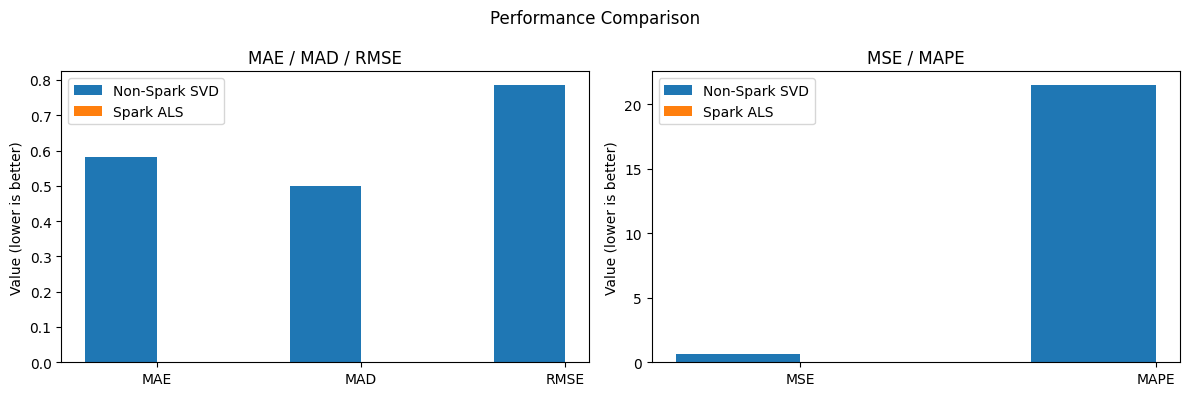

In [13]:
import matplotlib.pyplot as plt

def _safe_metric(metrics, key):
    if metrics is None:
        return np.nan
    return metrics.get(key, np.nan)


# Grouped metrics for clearer comparison (lower is better)
group1 = ["mae", "mad", "rmse"]
group2 = ["mse", "mape"]

sk_vals_g1 = [_safe_metric(metrics_sklearn, k) for k in group1]
sp_vals_g1 = [_safe_metric(metrics_spark, k) for k in group1]

sk_vals_g2 = [_safe_metric(metrics_sklearn, k) for k in group2]
sp_vals_g2 = [_safe_metric(metrics_spark, k) for k in group2]

x1 = np.arange(len(group1))
x2 = np.arange(len(group2))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(x1 - width / 2, sk_vals_g1, width, label="Non-Spark SVD")
axes[0].bar(x1 + width / 2, sp_vals_g1, width, label="Spark ALS")
axes[0].set_xticks(x1)
axes[0].set_xticklabels([k.upper() for k in group1])
axes[0].set_title("MAE / MAD / RMSE")
axes[0].set_ylabel("Value (lower is better)")
axes[0].legend()

axes[1].bar(x2 - width / 2, sk_vals_g2, width, label="Non-Spark SVD")
axes[1].bar(x2 + width / 2, sp_vals_g2, width, label="Spark ALS")
axes[1].set_xticks(x2)
axes[1].set_xticklabels([k.upper() for k in group2])
axes[1].set_title("MSE / MAPE")
axes[1].set_ylabel("Value (lower is better)")
axes[1].legend()

plt.suptitle("Performance Comparison")
plt.tight_layout()
plt.show()

## Graph Analytics (NetworkX)

This section performs deeper analytics on a **bipartite User–Movie graph** built from a manageable sample. We then:
1. Identify **hub movies** via degree centrality.
2. Project the graph into a **Movie–Movie network**.
3. Detect **communities** of movies that are frequently watched together.
4. Visualize the Movie–Movie graph with community colors.

These steps provide interpretable insights beyond simple visualization.

In [14]:
import networkx as nx
from networkx.algorithms import bipartite

# 1) Graph Construction (Bipartite)
max_users = 3000
max_movies = 500

_df = df_ratings.copy()
_df["title"] = _df["title"].astype(str).str.strip()

movie_id_to_title = (
    _df.drop_duplicates("movie_id")
    .set_index("movie_id")["title"]
    .to_dict()
)

Top_users = _df["customer_id"].value_counts().head(max_users).index.tolist()
Top_movies = _df["movie_id"].value_counts().head(max_movies).index.tolist()

filtered = _df[
    _df["customer_id"].isin(Top_users)
    & _df["movie_id"].isin(Top_movies)
].copy()

B = nx.Graph()
user_nodes = [f"U_{u}" for u in filtered["customer_id"].unique()]
movie_nodes = [f"M_{m}" for m in filtered["movie_id"].unique()]

B.add_nodes_from(user_nodes, bipartite=0, node_type="user")
B.add_nodes_from(movie_nodes, bipartite=1, node_type="movie")

for row in filtered.itertuples(index=False):
    user_node = f"U_{row.customer_id}"
    movie_node = f"M_{row.movie_id}"
    B.add_edge(user_node, movie_node, weight=row.rating)

print(f"Bipartite graph built: {B.number_of_nodes()} nodes, {B.number_of_edges()} edges")

Bipartite graph built: 3229 nodes, 15893 edges


In [15]:
# 2) Centrality Analysis (Movie hubs)
movie_degree_centrality = bipartite.degree_centrality(B, movie_nodes)
movie_top = sorted(movie_degree_centrality.items(), key=lambda x: x[1], reverse=True)[:10]

print("Top most central movies (by degree centrality):")
for movie_node, score in movie_top:
    movie_id = int(movie_node.split("_")[1])
    title = movie_id_to_title.get(movie_id, "Unknown")
    if title == 'Unknown':
        continue
    print(f"- {movie_id} | {title} | centrality={score:.4f}")

most_central_movie = movie_top[0] if movie_top else None

Top most central movies (by degree centrality):
- 241 | North by Northwest | centrality=0.5233
- 191 | X2: X-Men United | centrality=0.3283
- 175 | Reservoir Dogs | centrality=0.2913
- 197 | Taking Lives | centrality=0.2520
- 240 | Woman of the Year | centrality=0.2047
- 252 | Stuart Little 2 | centrality=0.1817
- 232 | Gross Anatomy | centrality=0.1790
- 30 | Something's Gotta Give | centrality=0.1693


In [16]:
# 3) Graph Projection (Movie-to-Movie)
movie_graph = bipartite.projected_graph(B, movie_nodes)
print(f"Movie-Movie graph: {movie_graph.number_of_nodes()} nodes, {movie_graph.number_of_edges()} edges")

Movie-Movie graph: 229 nodes, 6947 edges


In [17]:
# 4) Community Detection (Greedy Modularity)
if movie_graph.number_of_edges() > 0:
    communities = list(nx.algorithms.community.greedy_modularity_communities(movie_graph))
    print(f"Detected {len(communities)} movie communities")

    largest_community = max(communities, key=len)
    largest_titles = [
        movie_id_to_title.get(int(n.split("_")[1]), "Unknown")
        for n in sorted(largest_community)
    ]

    print("Largest community sample titles:")
    for t in largest_titles[:20]:
        print(f"- {t}")
else:
    communities = []
    largest_community = set()
    print("Movie-Movie graph has no edges. Community detection skipped.")

Detected 3 movie communities
Largest community sample titles:
- Complete Shamanic Princess
- No Way Back
- Full Frame: Documentary Shorts
- Duplex (Widescreen)
- The Eye of Vichy
- Dominion Tank Police Part 1 & 2
- Bear Cub
- Rambo: First Blood Part II
- Cube 2: Hypercube
- Cold Blooded
- Vampire Effect (aka Twins Effect)
- Mr. Vampire
- Darkwolf
- Drowning on Dry Land
- Arachnid
- Lucio Fulci: The Beyond
- GTO: Great Teacher Onizuka: Set 2
- Naked Lies
- Star Trek: Voyager: Season 1
- Lost in the Wild


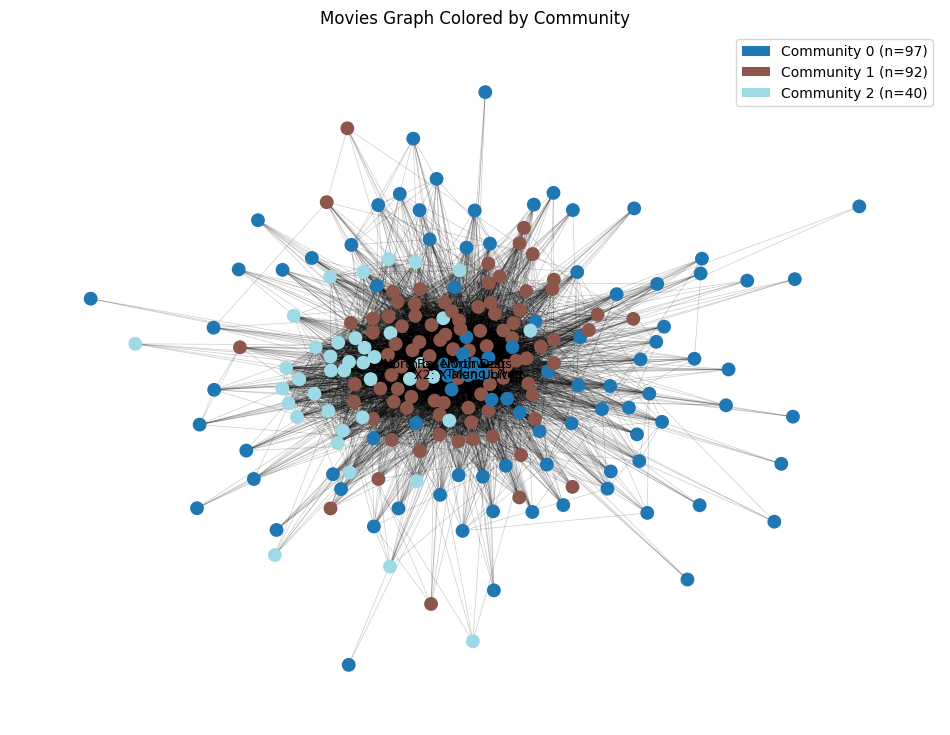

In [18]:
# 5) Advanced Visualization: Movie-Movie Graph colored by community
import numpy as np
from matplotlib import colormaps
from matplotlib.patches import Patch

plt.figure(figsize=(12, 9))

if movie_graph.number_of_nodes() == 0:
    print("Movie-Movie graph is empty. Nothing to visualize.")
else:
    pos = nx.spring_layout(movie_graph, seed=42, k=0.6)

    # Build community color map
    community_map = {}
    for idx, comm in enumerate(communities):
        for node in comm:
            community_map[node] = idx

    num_comms = max(community_map.values(), default=0) + 1
    base_cmap = colormaps["tab20"]
    color_palette = [base_cmap(x) for x in np.linspace(0, 1, max(num_comms, 1))]

    node_colors = [color_palette[community_map.get(n, 0)] for n in movie_graph.nodes()]

    nx.draw_networkx_edges(movie_graph, pos, alpha=0.2, width=0.5)
    nx.draw_networkx_nodes(movie_graph, pos, node_color=node_colors, node_size=80)

    # Label only the top central movies to keep the plot readable
    top_movie_nodes = [n for n, _ in movie_top[:5]]
    labels = {
        n: movie_id_to_title.get(int(n.split("_")[1]), "Unknown")
        for n in top_movie_nodes
        if n in movie_graph.nodes()
    }
    nx.draw_networkx_labels(movie_graph, pos, labels=labels, font_size=9)

    # Legend for top communities by size
    comm_sizes = sorted(
        [(i, len(c)) for i, c in enumerate(communities)],
        key=lambda x: x[1],
        reverse=True,
    )[:5]

    legend_elements = [
        Patch(facecolor=color_palette[i], label=f"Community {i} (n={size})")
        for i, size in comm_sizes
    ]

    plt.legend(handles=legend_elements, loc="upper right")
    plt.title("Movies Graph Colored by Community")
    plt.axis("off")
    plt.show()

### Graph Conclusion

- **Most influential movie:** the top entry in the degree-centrality list (printed above) is the most influential because it connects to the largest number of users.
- **Community structure:** the greedy modularity algorithm groups movies that are frequently watched together. The largest community often reflects a coherent theme (e.g., a genre cluster or a popular series), indicating the algorithm successfully captured shared viewing patterns in the sample.